# Actividad 9 integrada — Regresión Logística Multinomial

Este notebook reúne, en secciones independientes, los cuatro análisis de los archivos originales. No modifica esos archivos. Los datos se buscan en `Act9` y en la carpeta superior del proyecto. Los resultados del script se guardan en `Act9/resultados_integrados/` y las gráficas PNG en `Act9/resultados_integrados/graficas/`.

## Archivos de entrada
- `Datos_CLV_2026_Tec_v2.xlsx` (hojas de ventas, existencias, CRM, compras, salidas, metas y clasificación).
- `Datos_Complementarios_CLV.xlsx` (existencias, salidas y ventas).
- `Ventas_CLV_2022_2026.csv` para el análisis de clientes. Si no está disponible, se usa la hoja con el mismo nombre del Excel principal.

Ejecuta las celdas en orden. Cada sección mantiene su propio preprocesamiento, modelo, métricas y visualizaciones. Las gráficas se muestran en el notebook y también se exportan como imágenes PNG para usarlas en reportes.

In [1]:
from pathlib import Path

# El notebook puede ejecutarse desde Act9 o desde la carpeta del proyecto.
_cwd = Path.cwd()
_candidatos_act9 = [
    _cwd,
    _cwd / "Act9",
    _cwd / "ANOVA_repo" / "Act9",
    _cwd.parent / "Act9",
    _cwd.parent / "ANOVA_repo" / "Act9",
]
DIRECTORIO_ACT9 = next(
    (p.resolve() for p in _candidatos_act9 if p.is_dir() and p.name.lower() == "act9"),
    _cwd.resolve(),
)
DIRECTORIOS_DATOS = [DIRECTORIO_ACT9, DIRECTORIO_ACT9.parent, _cwd.resolve()]

def buscar_archivo(nombre):
    for directorio in dict.fromkeys(DIRECTORIOS_DATOS):
        candidato = directorio / nombre
        if candidato.is_file():
            return candidato
    return None

RUTA_PRINCIPAL = buscar_archivo("Datos_CLV_2026_Tec_v2.xlsx")
RUTA_COMPLEMENTARIA = buscar_archivo("Datos_Complementarios_CLV.xlsx")
RUTA_VENTAS_CSV = buscar_archivo("Ventas_CLV_2022_2026.csv")
if RUTA_PRINCIPAL is None:
    raise FileNotFoundError("No se encontro Datos_CLV_2026_Tec_v2.xlsx junto a Act9 o en la carpeta superior.")
if RUTA_COMPLEMENTARIA is None:
    raise FileNotFoundError("No se encontro Datos_Complementarios_CLV.xlsx junto a Act9 o en la carpeta superior.")

DIRECTORIO_RESULTADOS = DIRECTORIO_ACT9 / "resultados_integrados"
DIRECTORIO_RESULTADOS.mkdir(parents=True, exist_ok=True)
DIRECTORIO_GRAFICAS = DIRECTORIO_RESULTADOS / "graficas"
DIRECTORIO_GRAFICAS.mkdir(parents=True, exist_ok=True)

print(f"Datos principales: {RUTA_PRINCIPAL}")
print(f"Datos complementarios: {RUTA_COMPLEMENTARIA}")
print(f"Resultados de la version integrada: {DIRECTORIO_RESULTADOS}")
if RUTA_VENTAS_CSV is None:
    print("Ventas_CLV_2022_2026.csv no esta disponible; el analisis de clientes usara la hoja Ventas_CLV_2022_2026 del Excel principal.")


Datos principales: C:\Users\aomp2\OneDrive\Documentos\Arepo\ANOVA_repo\Act9\Datos_CLV_2026_Tec_v2.xlsx
Datos complementarios: C:\Users\aomp2\OneDrive\Documentos\Arepo\ANOVA_repo\Act9\Datos_Complementarios_CLV.xlsx
Resultados de la version integrada: C:\Users\aomp2\OneDrive\Documentos\Arepo\ANOVA_repo\Act9\resultados_integrados


## 1. Segmentación de clientes, métricas y gráficas

Cinco objetivos por cliente: CLV, frecuencia, ticket, diversidad de productos y volumen.

In [2]:
# Librerias para preprocesamiento, regresion multinomial y evaluacion
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

In [3]:
# Cargamos el archivo de ventas
# El CSV debe estar en la misma carpeta que este notebook.
if RUTA_VENTAS_CSV is not None:
    df = pd.read_csv(RUTA_VENTAS_CSV, encoding="utf-8-sig")
else:
    df = pd.read_excel(RUTA_PRINCIPAL, sheet_name="Ventas_CLV_2022_2026")
print(f"Registros: {len(df):,}; columnas: {df.shape[1]}")
df.head()

Registros: 114,501; columnas: 15


,fecha_documento,folio_abreviado,folio,articulo_id,clave_articulo,nombre_articulo,marca,precio_unitario,total_unidades,total_neto,nombre_cliente,estado,ciudad,cp,vendedor
0,11.09.2026,B00,B00013017,7688,MFTL374M2,MFT L37 4M2,VITA,172.413793,1,172.41,HUGO CARRILLO SANPEDRO SF,Ciudad de México,CDMX,6100.0,JAVIERCAD
1,11.09.2026,B00,B00013017,7895,MFTPL313R2.5,MFT PL31 3R2.5,VITA,172.413793,1,172.41,HUGO CARRILLO SANPEDRO SF,Ciudad de México,CDMX,6100.0,JAVIERCAD
2,11.09.2026,B00,B00013017,7985,MFTPU313R2.5,MFT PU31 3R2.5,VITA,172.413793,2,344.83,HUGO CARRILLO SANPEDRO SF,Ciudad de México,CDMX,6100.0,JAVIERCAD
3,11.09.2026,B00,B00013017,8258,MFTT464M2,MFT T46 4M2,VITA,172.413793,2,344.83,HUGO CARRILLO SANPEDRO SF,Ciudad de México,CDMX,6100.0,JAVIERCAD
4,11.09.2026,A00,A00018080,7613,MFTL332M2,MFT L33 2M2,VITA,156.740000,1,156.74,JUAN PEDRO OLVERA ALONSO,Querétaro,Querétaro,76079.0,SERGIO SANCHEZ


In [4]:
# Revisamos valores faltantes y convertimos la fecha
nulos = df.isna().sum().sort_values(ascending=False)
print("Valores nulos por columna:")
display(nulos.rename("Nulos").to_frame())

df["fecha_documento"] = pd.to_datetime(
    df["fecha_documento"], dayfirst=True, errors="coerce"
)
print("Fechas no convertibles:", int(df["fecha_documento"].isna().sum()))
print("Periodo observado:", df["fecha_documento"].min(), "a", df["fecha_documento"].max())
anios_observados = set(df["fecha_documento"].dt.year.dropna().astype(int))
anios_sin_registros = sorted(set(range(2022, 2027)) - anios_observados)
print("Anios 2022-2026 sin registros:", anios_sin_registros)

df = df.drop(columns=["cp"])

Valores nulos por columna:


,Nulos
cp,5188
folio_abreviado,0
fecha_documento,0
articulo_id,0
clave_articulo,0
nombre_articulo,0
folio,0
marca,0
precio_unitario,0
total_neto,0


Fechas no convertibles: 0
Periodo observado: 2023-01-02 00:00:00 a 2026-09-11 00:00:00
Anios 2022-2026 sin registros: [2022]


In [5]:
# Agregamos las transacciones a nivel cliente
def obtener_moda(serie):
    modas = serie.mode()
    return modas.iloc[0] if not modas.empty else "Sin dato"

clientes = df.groupby("nombre_cliente").agg(
    ventas_totales=("total_neto", "sum"),
    facturas=("folio", "nunique"),
    unidades_totales=("total_unidades", "sum"),
    productos_distintos=("clave_articulo", "nunique"),
    marcas_distintas=("marca", "nunique"),
    precio_promedio=("precio_unitario", "mean"),
    estado=("estado", obtener_moda),
    ciudad=("ciudad", obtener_moda),
    vendedor=("vendedor", obtener_moda),
)
clientes["ticket_promedio"] = clientes["ventas_totales"] / clientes["facturas"].clip(lower=1)

# Creamos cinco objetivos categoricos de tres clases.
etiquetas_terciles = ["Bajo", "Medio", "Alto"]
clientes["CLV"] = pd.qcut(clientes["ventas_totales"], q=3, labels=etiquetas_terciles)
clientes["Frecuencia"] = pd.cut(
    clientes["facturas"],
    bins=[0, 1, 3, np.inf],
    labels=["Unica", "Ocasional", "Recurrente"],
    include_lowest=True,
)
clientes["Ticket"] = pd.qcut(clientes["ticket_promedio"], q=3, labels=etiquetas_terciles)
clientes["Diversidad"] = pd.qcut(clientes["productos_distintos"], q=3, labels=etiquetas_terciles)
clientes["Volumen"] = pd.qcut(clientes["unidades_totales"], q=3, labels=etiquetas_terciles)
print(f"Clientes analizados: {len(clientes):,}")
clientes.head()

Clientes analizados: 4,743


,ventas_totales,facturas,unidades_totales,productos_distintos,marcas_distintas,precio_promedio,estado,ciudad,vendedor,ticket_promedio,CLV,Frecuencia,Ticket,Diversidad,Volumen
nombre_cliente,,,,,,,,,,,,,,,
MARTHA CUELLAR PIÑA,8534.48,1,3,3,1,2844.827333,Querétaro,Corregidora,RENE,8534.480,Medio,Unica,Medio,Bajo,Bajo
3D DIGITAL DENTAL DESIGN,84579.24,12,69,26,4,1196.356104,Coahuila,Torreón,CLAUDIA,7048.270,Alto,Recurrente,Medio,Alto,Alto
3D FACTORY MEXICO,55356.90,2,9,9,1,6150.766667,Nuevo León,Monterrey,GERARDO / BO ENRIQUE,27678.450,Alto,Ocasional,Alto,Alto,Medio
A W A INFRAESTRUCTURA,724.12,1,4,4,1,181.034400,Michoacán,Michoacan,EFREN,724.120,Bajo,Unica,Bajo,Medio,Medio
AARON RICARDO DEL ANGEL ZAMACONA SF,1810.33,2,5,5,2,362.066000,Tamaulipas,Tampico,GERARDO,905.165,Bajo,Ocasional,Bajo,Medio,Medio


In [6]:
# Detectamos valores extremos mediante la regla de 1.5 veces el rango intercuartilico
# No se eliminan ni limitan: los grandes clientes pueden ser observaciones validas.
variables_a_revisar = [
    "ventas_totales", "facturas", "unidades_totales",
    "productos_distintos", "marcas_distintas", "precio_promedio", "ticket_promedio",
]
reporte_outliers = []
for variable in variables_a_revisar:
    valores = clientes[variable].dropna()
    q1, q3 = valores.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    extremos = ((valores < limite_inferior) | (valores > limite_superior)).sum()
    reporte_outliers.append({
        "Variable": variable,
        "Limite inferior IQR": limite_inferior,
        "Limite superior IQR": limite_superior,
        "Valores extremos": int(extremos),
    })
display(pd.DataFrame(reporte_outliers).set_index("Variable"))

objetivos = ["CLV", "Frecuencia", "Ticket", "Diversidad", "Volumen"]
for objetivo in objetivos:
    print(f"\nDistribucion de {objetivo}:")
    display(clientes[objetivo].value_counts().rename_axis(objetivo).to_frame("Clientes"))

,Limite inferior IQR,Limite superior IQR,Valores extremos
Variable,,,
ventas_totales,-120667.220000,207525.820000,467
facturas,-3.500000,8.500000,686
unidades_totales,-22.000000,42.000000,669
productos_distintos,-11.500000,24.500000,565
marcas_distintas,-0.500000,3.500000,626
precio_promedio,-9227.136091,16556.971278,843
ticket_promedio,-31249.998750,55370.691250,765



Distribucion de CLV:


,Clientes
CLV,
Bajo,1581
Medio,1581
Alto,1581



Distribucion de Frecuencia:


,Clientes
Frecuencia,
Unica,2212
Recurrente,1377
Ocasional,1154



Distribucion de Ticket:


,Clientes
Ticket,
Bajo,1581
Medio,1581
Alto,1581



Distribucion de Diversidad:


,Clientes
Diversidad,
Bajo,1954
Alto,1458
Medio,1331



Distribucion de Volumen:


,Clientes
Volumen,
Bajo,1710
Alto,1545
Medio,1488


In [7]:
# Definimos los predictores excluyendo las variables que definen cada objetivo
variables_categoricas = ["estado", "ciudad", "vendedor"]
experimentos = {
    "CLV por ventas netas": {
        "objetivo": "CLV",
        "numericas": ["facturas", "unidades_totales", "productos_distintos", "marcas_distintas"],
    },
    "Frecuencia de compra": {
        "objetivo": "Frecuencia",
        "numericas": ["unidades_totales", "productos_distintos", "marcas_distintas"],
    },
    "Ticket promedio": {
        "objetivo": "Ticket",
        "numericas": ["facturas", "unidades_totales", "productos_distintos", "marcas_distintas"],
    },
    "Diversidad de productos": {
        "objetivo": "Diversidad",
        "numericas": ["facturas", "unidades_totales", "marcas_distintas"],
    },
    "Volumen de unidades": {
        "objetivo": "Volumen",
        "numericas": ["facturas", "productos_distintos", "marcas_distintas"],
    },
}

preparador_numerico = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="median")),
    ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("estandarizacion", StandardScaler()),
])
preparador_categorico = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore")),
])

In [8]:
# Entrenamos y evaluamos un modelo multinomial independiente para cada objetivo
resultados = {}
for nombre, especificacion in experimentos.items():
    objetivo = especificacion["objetivo"]
    variables_numericas = especificacion["numericas"]
    predictores = variables_numericas + variables_categoricas
    X = clientes[predictores]
    y = clientes[objetivo].astype(str)
    etiquetas = clientes[objetivo].cat.categories.astype(str).tolist()

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, random_state=42, stratify=y
    )
    preprocesamiento = ColumnTransformer(transformers=[
        ("numericas", preparador_numerico, variables_numericas),
        ("categoricas", preparador_categorico, variables_categoricas),
    ])
    modelo = Pipeline(steps=[
        ("preprocesamiento", preprocesamiento),
        ("clasificador", LogisticRegression(solver="lbfgs", max_iter=2000)),
    ])
    modelo.fit(X_train, y_train)
    predicciones = modelo.predict(X_test)
    matriz = confusion_matrix(y_test, predicciones, labels=etiquetas)

    resultados[nombre] = {
        "objetivo": objetivo,
        "etiquetas": etiquetas,
        "matriz": matriz,
        "precision_macro": precision_score(y_test, predicciones, average="macro", zero_division=0),
        "exactitud": accuracy_score(y_test, predicciones),
        "sensibilidad_macro": recall_score(y_test, predicciones, average="macro", zero_division=0),
        "reporte": classification_report(
            y_test, predicciones, labels=etiquetas, zero_division=0, output_dict=True
        ),
    }

    print(f"\n=== {nombre} ===")
    print("Predictores numericos:", variables_numericas)
    print("Predictores categoricos:", variables_categoricas)
    print("Precision macro:", round(resultados[nombre]["precision_macro"], 4))
    print("Exactitud:", round(resultados[nombre]["exactitud"], 4))
    print("Sensibilidad (recall macro):", round(resultados[nombre]["sensibilidad_macro"], 4))
    print("Matriz de confusion (filas=real; columnas=prediccion; orden:", etiquetas, ")")
    display(pd.DataFrame(matriz, index=etiquetas, columns=etiquetas))


=== CLV por ventas netas ===
Predictores numericos: ['facturas', 'unidades_totales', 'productos_distintos', 'marcas_distintas']
Predictores categoricos: ['estado', 'ciudad', 'vendedor']
Precision macro: 0.6186
Exactitud: 0.6226
Sensibilidad (recall macro): 0.6227
Matriz de confusion (filas=real; columnas=prediccion; orden: ['Bajo', 'Medio', 'Alto'] )


,Bajo,Medio,Alto
Bajo,355,91,28
Medio,112,231,132
Alto,74,100,300



=== Frecuencia de compra ===
Predictores numericos: ['unidades_totales', 'productos_distintos', 'marcas_distintas']
Predictores categoricos: ['estado', 'ciudad', 'vendedor']
Precision macro: 0.7005
Exactitud: 0.7358
Sensibilidad (recall macro): 0.6879
Matriz de confusion (filas=real; columnas=prediccion; orden: ['Unica', 'Ocasional', 'Recurrente'] )


,Unica,Ocasional,Recurrente
Unica,581,51,32
Ocasional,159,129,58
Recurrente,21,55,337



=== Ticket promedio ===
Predictores numericos: ['facturas', 'unidades_totales', 'productos_distintos', 'marcas_distintas']
Predictores categoricos: ['estado', 'ciudad', 'vendedor']
Precision macro: 0.5611
Exactitud: 0.5657
Sensibilidad (recall macro): 0.5658
Matriz de confusion (filas=real; columnas=prediccion; orden: ['Bajo', 'Medio', 'Alto'] )


,Bajo,Medio,Alto
Bajo,341,83,50
Medio,129,203,143
Alto,105,108,261



=== Diversidad de productos ===
Predictores numericos: ['facturas', 'unidades_totales', 'marcas_distintas']
Predictores categoricos: ['estado', 'ciudad', 'vendedor']
Precision macro: 0.8414
Exactitud: 0.8503
Sensibilidad (recall macro): 0.8412
Matriz de confusion (filas=real; columnas=prediccion; orden: ['Bajo', 'Medio', 'Alto'] )


,Bajo,Medio,Alto
Bajo,529,51,6
Medio,58,296,45
Alto,0,53,385



=== Volumen de unidades ===
Predictores numericos: ['facturas', 'productos_distintos', 'marcas_distintas']
Predictores categoricos: ['estado', 'ciudad', 'vendedor']
Precision macro: 0.8799
Exactitud: 0.8805
Sensibilidad (recall macro): 0.8793
Matriz de confusion (filas=real; columnas=prediccion; orden: ['Bajo', 'Medio', 'Alto'] )


,Bajo,Medio,Alto
Bajo,462,51,0
Medio,26,376,44
Alto,4,45,415


In [9]:
# Comparamos las metricas solicitadas y mostramos el reporte por clase
resumen = pd.DataFrame([
    {
        "Analisis": nombre,
        "Precision macro": resultado["precision_macro"],
        "Exactitud": resultado["exactitud"],
        "Sensibilidad macro": resultado["sensibilidad_macro"],
    }
    for nombre, resultado in resultados.items()
]).set_index("Analisis")
display(resumen.round(4))

for nombre, resultado in resultados.items():
    print(f"\nReporte por clase: {nombre}")
    display(pd.DataFrame(resultado["reporte"]).T.round(3))

,Precision macro,Exactitud,Sensibilidad macro
Analisis,,,
CLV por ventas netas,0.6186,0.6226,0.6227
Frecuencia de compra,0.7005,0.7358,0.6879
Ticket promedio,0.5611,0.5657,0.5658
Diversidad de productos,0.8414,0.8503,0.8412
Volumen de unidades,0.8799,0.8805,0.8793



Reporte por clase: CLV por ventas netas


,precision,recall,f1-score,support
Bajo,0.656,0.749,0.700,474.000
Medio,0.547,0.486,0.515,475.000
Alto,0.652,0.633,0.642,474.000
accuracy,0.623,0.623,0.623,0.623
macro avg,0.619,0.623,0.619,1423.000
weighted avg,0.619,0.623,0.619,1423.000



Reporte por clase: Frecuencia de compra


,precision,recall,f1-score,support
Unica,0.763,0.875,0.815,664.000
Ocasional,0.549,0.373,0.444,346.000
Recurrente,0.789,0.816,0.802,413.000
accuracy,0.736,0.736,0.736,0.736
macro avg,0.701,0.688,0.687,1423.000
weighted avg,0.719,0.736,0.721,1423.000



Reporte por clase: Ticket promedio


,precision,recall,f1-score,support
Bajo,0.593,0.719,0.650,474.000
Medio,0.515,0.427,0.467,475.000
Alto,0.575,0.551,0.562,474.000
accuracy,0.566,0.566,0.566,0.566
macro avg,0.561,0.566,0.560,1423.000
weighted avg,0.561,0.566,0.560,1423.000



Reporte por clase: Diversidad de productos


,precision,recall,f1-score,support
Bajo,0.901,0.903,0.902,586.00
Medio,0.740,0.742,0.741,399.00
Alto,0.883,0.879,0.881,438.00
accuracy,0.850,0.850,0.850,0.85
macro avg,0.841,0.841,0.841,1423.00
weighted avg,0.850,0.850,0.850,1423.00



Reporte por clase: Volumen de unidades


,precision,recall,f1-score,support
Bajo,0.939,0.901,0.919,513.000
Medio,0.797,0.843,0.819,446.000
Alto,0.904,0.894,0.899,464.000
accuracy,0.881,0.881,0.881,0.881
macro avg,0.880,0.879,0.879,1423.000
weighted avg,0.883,0.881,0.881,1423.000


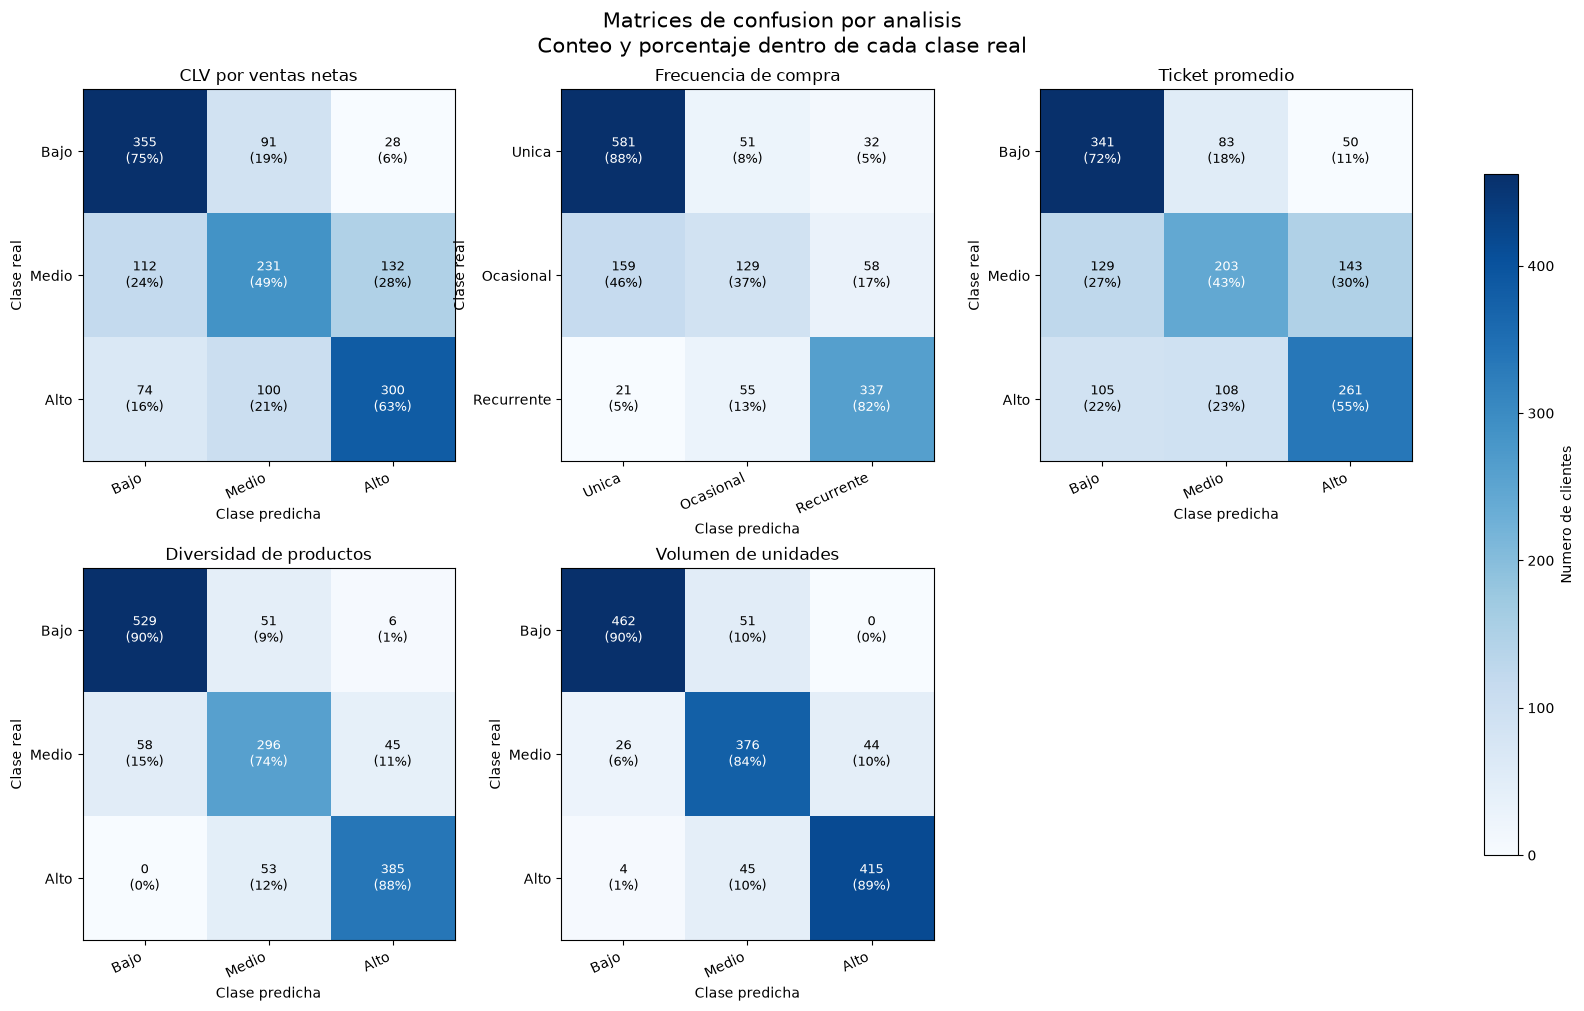

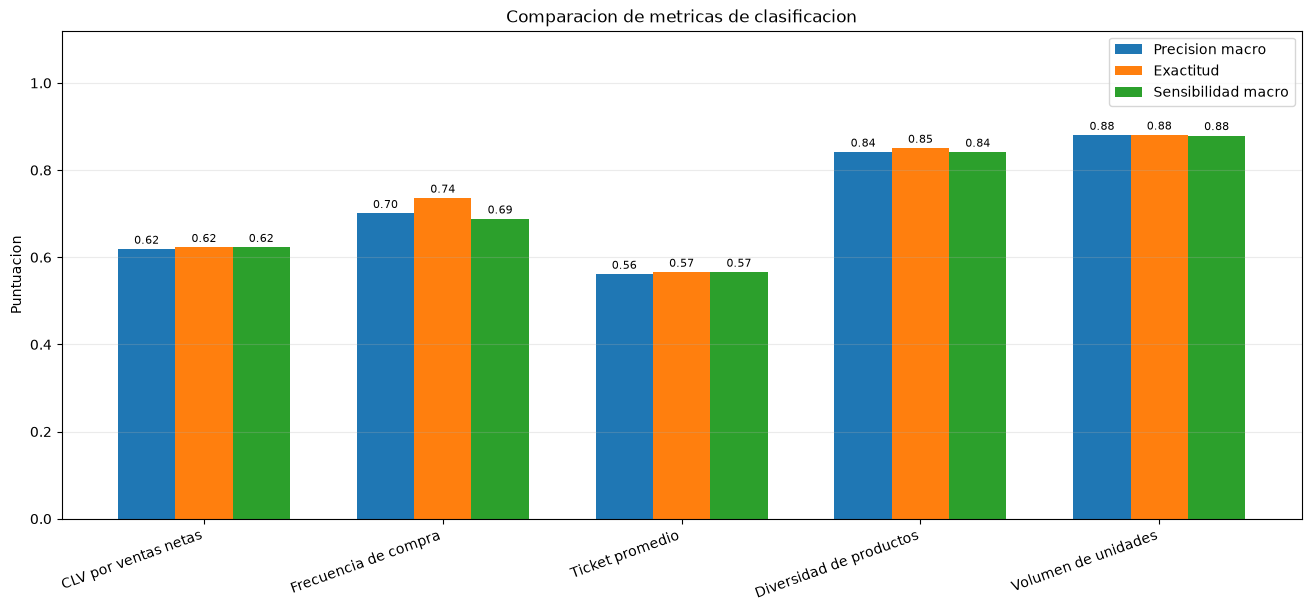

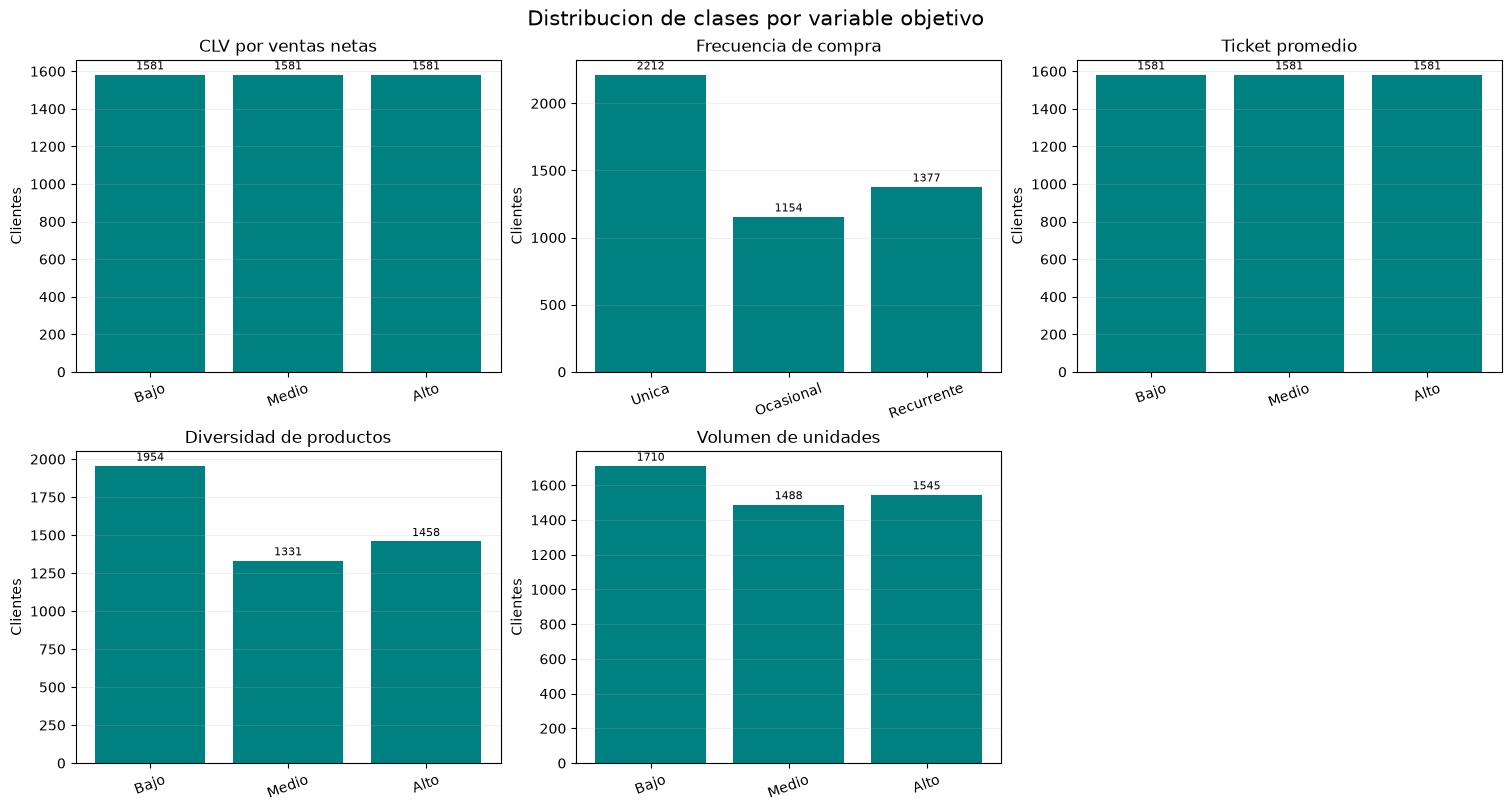

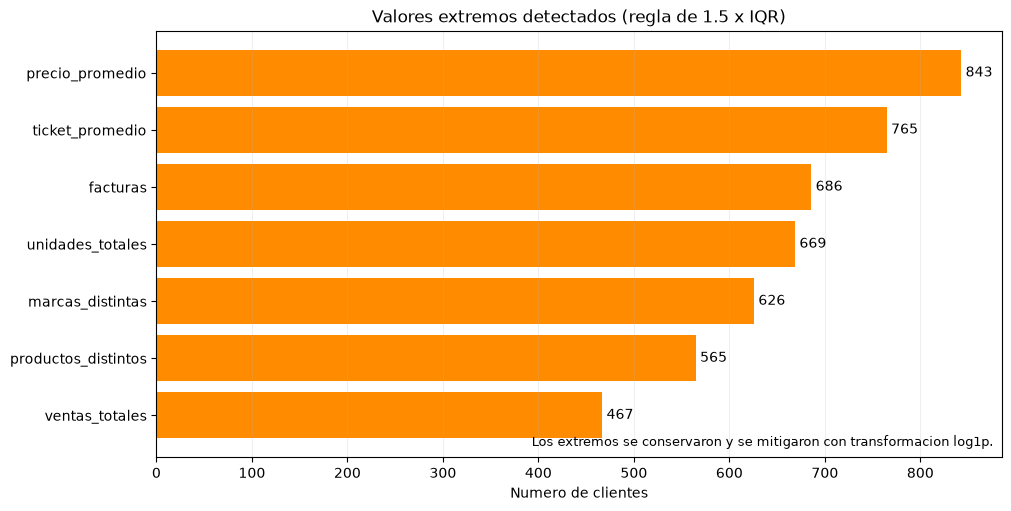

In [10]:
import matplotlib.pyplot as plt

# Matrices de confusion: filas = clase real; columnas = clase predicha.
fig, axes = plt.subplots(2, 3, figsize=(16, 10), constrained_layout=True)
for ax, (nombre, resultado) in zip(axes.flat, resultados.items()):
    matriz = resultado["matriz"]
    etiquetas = resultado["etiquetas"]
    imagen = ax.imshow(matriz, cmap="Blues")
    ax.set_title(nombre)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_xticks(range(len(etiquetas)), etiquetas, rotation=25, ha="right")
    ax.set_yticks(range(len(etiquetas)), etiquetas)
    totales_reales = matriz.sum(axis=1)
    for fila in range(matriz.shape[0]):
        for columna in range(matriz.shape[1]):
            porcentaje = matriz[fila, columna] / totales_reales[fila] if totales_reales[fila] else 0
            color = "white" if matriz[fila, columna] > matriz.max() / 2 else "black"
            ax.text(
                columna,
                fila,
                f"{matriz[fila, columna]}{chr(10)}({porcentaje:.0%})",
                ha="center",
                va="center",
                color=color,
                fontsize=9,
            )
axes.flat[-1].axis("off")
fig.colorbar(imagen, ax=axes.ravel().tolist()[:-1], shrink=0.8, label="Numero de clientes")
fig.suptitle("Matrices de confusion por analisis" + chr(10) + "Conteo y porcentaje dentro de cada clase real", fontsize=15)
fig.savefig(DIRECTORIO_GRAFICAS / "clientes_matrices_confusion.png", dpi=180, bbox_inches="tight")
fig.savefig(DIRECTORIO_GRAFICAS / "clientes_comparacion_metricas.png", dpi=180, bbox_inches="tight")
fig.savefig(DIRECTORIO_GRAFICAS / "clientes_distribucion_clases.png", dpi=180, bbox_inches="tight")
fig.savefig(DIRECTORIO_GRAFICAS / "clientes_valores_extremos.png", dpi=180, bbox_inches="tight")
plt.show()

# Comparacion directa de precision macro, exactitud y sensibilidad macro.
nombres = resumen.index.tolist()
metricas = ["Precision macro", "Exactitud", "Sensibilidad macro"]
posiciones = np.arange(len(nombres))
ancho = 0.24
fig, ax = plt.subplots(figsize=(13, 6), constrained_layout=True)
for indice, metrica in enumerate(metricas):
    valores = resumen[metrica].to_numpy()
    barras = ax.bar(posiciones + (indice - 1) * ancho, valores, ancho, label=metrica)
    ax.bar_label(barras, fmt="%.2f", padding=2, fontsize=8)
ax.set_title("Comparacion de metricas de clasificacion")
ax.set_ylabel("Puntuacion")
ax.set_ylim(0, 1.12)
ax.set_xticks(posiciones, nombres, rotation=20, ha="right")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper right")
plt.show()

# Balance de las categorias objetivo en los clientes analizados.
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for ax, (nombre, especificacion) in zip(axes.flat, experimentos.items()):
    objetivo = especificacion["objetivo"]
    conteos = clientes[objetivo].value_counts(sort=False)
    barras = ax.bar(conteos.index.astype(str), conteos.values, color="teal")
    ax.bar_label(barras, fmt="%d", padding=2, fontsize=8)
    ax.set_title(nombre)
    ax.set_ylabel("Clientes")
    ax.tick_params(axis="x", labelrotation=20)
    ax.grid(axis="y", alpha=0.2)
axes.flat[-1].axis("off")
fig.suptitle("Distribucion de clases por variable objetivo", fontsize=15)
plt.show()

# Cantidad de valores extremos detectados por variable con la regla IQR.
outliers_grafica = pd.DataFrame(reporte_outliers).sort_values("Valores extremos")
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
barras = ax.barh(outliers_grafica["Variable"], outliers_grafica["Valores extremos"], color="darkorange")
ax.bar_label(barras, fmt="%d", padding=3)
ax.set_title("Valores extremos detectados (regla de 1.5 x IQR)")
ax.set_xlabel("Numero de clientes")
ax.text(
    0.99,
    0.02,
    "Los extremos se conservaron y se mitigaron con transformacion log1p.",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
)
ax.grid(axis="x", alpha=0.2)
plt.show()

## 2. Clasificación de marcas con existencias

Combina existencias y valor de inventario con TF-IDF del nombre del artículo.

Marcas a clasificar (18 categorías):
marca_modelo
Vita              1806
Amann Girrbach     307
Creation           243
Aidite             194
Anax Dent          121
Huge                88
Jensen              50
Scheftner           28
Otras_Marcas        27
Phrozen             23
Asiga               13
Hass                11
Medit                9
Roko                 8
Dekema               6
Renfert              6
Dess                 5
Exocad               5
Name: count, dtype: int64


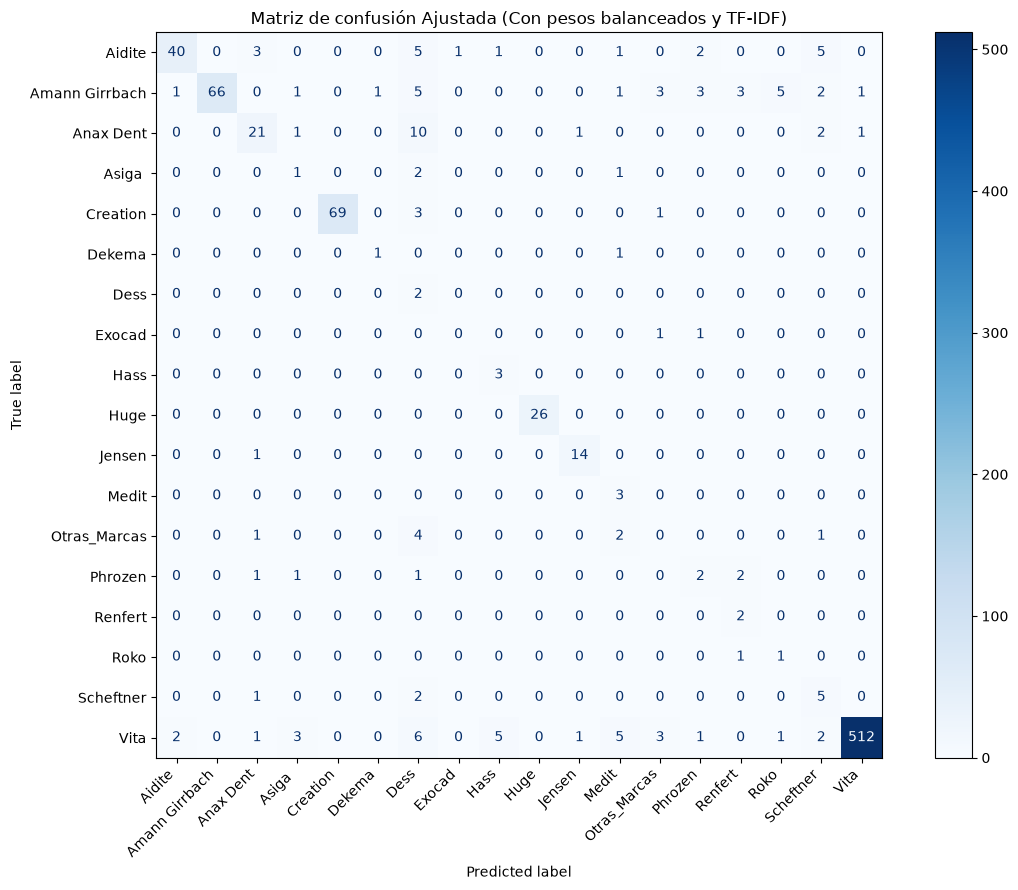


Exactitud del modelo: 0.8678

Reporte de Clasificación Detallado:
                precision    recall  f1-score   support

        Aidite       0.93      0.69      0.79        58
Amann Girrbach       1.00      0.72      0.84        92
     Anax Dent       0.72      0.58      0.65        36
        Asiga        0.14      0.25      0.18         4
      Creation       1.00      0.95      0.97        73
        Dekema       0.50      0.50      0.50         2
          Dess       0.05      1.00      0.10         2
        Exocad       0.00      0.00      0.00         2
          Hass       0.33      1.00      0.50         3
          Huge       1.00      1.00      1.00        26
        Jensen       0.88      0.93      0.90        15
         Medit       0.21      1.00      0.35         3
  Otras_Marcas       0.00      0.00      0.00         8
       Phrozen       0.22      0.29      0.25         7
       Renfert       0.25      1.00      0.40         2
          Roko       0.14      0.50 

In [11]:
# ==========================================
# 1. Cargamos librerías
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report
)
from scipy.sparse import hstack

# ==========================================
# 2. Carga y preparación inicial del Excel
# ==========================================
df = pd.read_excel(RUTA_PRINCIPAL, sheet_name="Existencias_04_09_2026")
df.columns = df.columns.astype(str).str.strip()

# Identificación precisa de columnas
col_existencia = [c for c in df.columns if 'existenc' in c.lower()][0]
col_valor = [c for c in df.columns if 'valor' in c.lower()][0]
col_marca = [c for c in df.columns if 'marca' in c.lower()][0]

# Priorizamos 'nombre_articulo' para evitar tomar el código entero de la columna A
cols_nombre = [c for c in df.columns if 'nombre_articulo' in c.lower()]
col_articulo = cols_nombre[0] if cols_nombre else [c for c in df.columns if 'articulo' in c.lower()][0]

# Eliminamos registros sin marca
df = df.dropna(subset=[col_marca]).copy()

# ==========================================
# 3. Agrupación de marcas poco frecuentes
# ==========================================
UMBRAL_REGISTROS = 5
conteo_marcas = df[col_marca].value_counts()
marcas_principales = conteo_marcas[conteo_marcas >= UMBRAL_REGISTROS].index

df['marca_modelo'] = df[col_marca].apply(
    lambda x: x if x in marcas_principales else 'Otras_Marcas'
)

print(f"Marcas a clasificar ({len(df['marca_modelo'].unique())} categorías):")
print(df['marca_modelo'].value_counts())

# ==========================================
# 4. Limpieza de nulos y Conversión a String
# ==========================================
df[col_existencia] = df[col_existencia].fillna(0)
df[col_valor] = df[col_valor].fillna(0)

# CONVERSIÓN CRÍTICA A CADENA DE TEXTO (evita AttributeError)
df[col_articulo] = df[col_articulo].fillna('').astype(str)

# Variable de Precio Unitario (evitando división por 0)
df['precio_unitario'] = np.where(
    df[col_existencia] > 0, 
    df[col_valor] / df[col_existencia], 
    0
)

# ==========================================
# 5. Construcción de características (X)
# ==========================================
# A) Numéricas escaladas
num_features = df[[col_existencia, col_valor, 'precio_unitario']]
escalar = StandardScaler()
X_num_scaled = escalar.fit_transform(num_features)

# B) Texto con TF-IDF
tfidf = TfidfVectorizer(max_features=100)
X_text_tfidf = tfidf.fit_transform(df[col_articulo])

# C) Matriz combinada
X_combined = hstack([X_num_scaled, X_text_tfidf])
y = df['marca_modelo']

# ==========================================
# 6. División en Entrenamiento y Prueba
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X_combined, y, test_size=0.3, random_state=42, stratify=y
)

# ==========================================
# 7. Regresión Logística Multinomial
# ==========================================
algoritmo = LogisticRegression(
    solver='lbfgs',
    max_iter=2000,
    class_weight='balanced',
    random_state=42
)
algoritmo.fit(X_train, y_train)

# ==========================================
# 8. Evaluación y Gráficos
# ==========================================
y_pred = algoritmo.predict(X_test)

matriz = confusion_matrix(y_test, y_pred, labels=algoritmo.classes_)

fig, ax = plt.subplots(figsize=(12, 9))
disp = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=algoritmo.classes_)
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Matriz de confusión Ajustada (Con pesos balanceados y TF-IDF)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
fig.savefig(DIRECTORIO_GRAFICAS / "existencias_matriz_confusion_marcas.png", dpi=180, bbox_inches="tight")
plt.show()

print("\nExactitud del modelo:", round(accuracy_score(y_test, y_pred), 4))
print("\nReporte de Clasificación Detallado:")
print(classification_report(y_test, y_pred, zero_division=0))

Implementación del modelo: Se desarrolló un algoritmo de Regresión Logística Multinomial para clasificar automáticamente la variable dependiente marca.

Variables predictoras y su tratamiento:

Variables cuantitativas: Se utilizaron existencia y valor_total_inventario, ambas estandarizadas mediante StandardScaler. Además, se incorporó la variable derivada precio_unitario (valor_total_inventario / existencia) para diferenciar segmentos de costo entre productos.

Variable cualitativa (texto): La variable nombre_articulo fue procesada mediante TF-IDF para extraer términos y patrones distintivos que facilitan la identificación de las diferentes marcas.

Ajuste de datos: Para garantizar una partición estratificada adecuada, las marcas con menos de cinco registros fueron agrupadas en la categoría Otras_Marcas.

Control de sesgo: Se utilizó el parámetro class_weight='balanced' para compensar el desbalance de clases, penalizando los errores en las categorías minoritarias y evitando que el modelo favoreciera excesivamente a la marca predominante (Vita).

Resultados: El modelo produjo una matriz de confusión equilibrada y mostró un alto nivel de precisión en marcas relevantes como Aidite (40 aciertos), Amann Girrbach (66), Creation (69), Huge (26) y Vita (510).

Evaluación: Los valores bajos observados (por ejemplo, "1" o "2") corresponden a aciertos puntuales en el conjunto de prueba, que representó el 30 % de los datos, para marcas con una presencia reducida en el inventario.

Conclusión e impacto: La integración de variables cuantitativas, técnicas de procesamiento de texto y estrategias de balanceo de clases permitió construir una herramienta eficaz para automatizar la clasificación de marcas en el inventario. Esto contribuye a reducir errores de registro, mejorar la calidad de los datos y optimizar los procesos de gestión comercial.

## 3. Clasificación de marcas en existencias, salidas y ventas

Usa las tres hojas de `Datos_Complementarios_CLV.xlsx` y compara los tres modelos.

# Actividad 9 - Regresión Logística Multinomial
Se predice la marca en cada una de las 3 hojas de `Datos_Complementarios_CLV.xlsx` usando solo las variables numéricas de la hoja.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, classification_report

## 1. Carga

In [13]:
archivo = RUTA_COMPLEMENTARIA
exi = pd.read_excel(archivo, sheet_name=0)
sal = pd.read_excel(archivo, sheet_name=1)
ven = pd.read_excel(archivo, sheet_name=2)
for d in [exi, sal, ven]:
    d.columns = [c.strip() for c in d.columns]
print(exi.shape, sal.shape, ven.shape)

(2951, 6) (55180, 7) (21632, 14)


## 2. Preprocesamiento

In [14]:
# nulos y duplicados
print(exi.isna().sum().sum(), sal.isna().sum().sum(), ven.isna().sum().sum())
print(exi.duplicated().sum(), sal.duplicated().sum(), ven.duplicated().sum())

ven['cp'] = ven['cp'].fillna(ven['cp'].median())
ven = ven.drop_duplicates()
ven = ven[ven['precio_unitario'] > 0]

# marcas en mayuscula
exi['marca'] = exi['marca'].str.strip().str.upper()
sal['MARCA'] = sal['MARCA'].str.strip().str.upper()
ven['marc'] = ven['marc'].str.strip().str.upper()

0 0 492
0 0 185


In [15]:
# transformacion logaritmica de las variables asimetricas
exi['log_existencias'] = np.log1p(exi['existencias'])
exi['log_valor'] = np.log1p(exi['valor_inventario'])
sal['log_salidas'] = np.log1p(sal['SALIDAS'])
ven['log_precio'] = np.log1p(ven['precio_unitario'])
ven['log_unidades'] = np.log1p(ven['total_unidades'])
ven['log_total'] = np.log1p(ven['total_neto'])

# outliers con IQR x3 sobre las variables en log
def quitar_outliers(d, cols):
    ok = pd.Series(True, index=d.index)
    for c in cols:
        q1, q3 = d[c].quantile([.25, .75])
        iqr = q3 - q1
        ok &= d[c].between(q1 - 3 * iqr, q3 + 3 * iqr)
    print('outliers eliminados:', (~ok).sum())
    return d[ok].copy()

exi = quitar_outliers(exi, ['log_existencias', 'log_valor'])
sal = quitar_outliers(sal, ['log_salidas'])
ven = quitar_outliers(ven, ['log_precio', 'log_unidades', 'log_total'])

outliers eliminados: 83
outliers eliminados: 2
outliers eliminados: 1387


## 3. Categorías de marca
Las marcas con menos de 10 registros se agrupan en OTRAS para poder dividir en entrenamiento y prueba.

In [16]:
def agrupar(m):
    n = m.value_counts()
    return m.where(~m.isin(n[n < 10].index), 'OTRAS')

exi['Marca_Existencias'] = agrupar(exi['marca'])
sal['Marca_Salidas'] = agrupar(sal['MARCA'])
ven['Marca_Ventas'] = agrupar(ven['marc'])

analisis = {
    'Marca_Existencias': (exi, ['log_existencias', 'log_valor']),
    'Marca_Salidas': (sal, ['ANO', 'MES', 'log_salidas']),
    'Marca_Ventas': (ven, ['log_precio', 'log_unidades', 'log_total', 'cp']),
}
for v, (d, cols) in analisis.items():
    print(v, d[v].nunique(), 'categorías')

Marca_Existencias 12 categorías
Marca_Salidas 30 categorías
Marca_Ventas 16 categorías


## 4. Regresión logística multinomial
Se usa 70% para entrenar y 30% para probar.

In [17]:
resultados = []
matrices = {}
for v, (d, cols) in analisis.items():
    X, y = d[cols], d[v]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
    modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    modelo.fit(Xtr, ytr)
    pred = modelo.predict(Xte)
    clases = sorted(y.unique())
    matrices[v] = (confusion_matrix(yte, pred, labels=clases), clases)
    resultados.append({'Variable': v,
                       'Categorías': len(clases),
                       'Exactitud': accuracy_score(yte, pred),
                       'Precisión': precision_score(yte, pred, average='macro', zero_division=0),
                       'Sensibilidad': recall_score(yte, pred, average='macro', zero_division=0)})
    print(v)
    print(classification_report(yte, pred, zero_division=0))

pd.DataFrame(resultados).round(3)

Marca_Existencias
                precision    recall  f1-score   support

        AIDITE       0.79      0.52      0.63        63
AMANN GIRRBACH       0.46      0.51      0.48        91
     ANAX DENT       0.00      0.00      0.00        28
         ASIGA       0.00      0.00      0.00         4
      CREATION       0.00      0.00      0.00        72
          HASS       0.00      0.00      0.00         3
          HUGE       0.96      1.00      0.98        27
        JENSEN       0.00      0.00      0.00        13
         OTRAS       0.00      0.00      0.00        18
       PHROZEN       0.00      0.00      0.00         6
     SCHEFTNER       0.00      0.00      0.00         8
          VITA       0.74      0.96      0.83       528

      accuracy                           0.71       861
     macro avg       0.25      0.25      0.24       861
  weighted avg       0.59      0.71      0.64       861

Marca_Salidas
                precision    recall  f1-score   support

         3DG

,Variable,Categorías,Exactitud,Precisión,Sensibilidad
0,Marca_Existencias,12,0.711,0.245,0.249
1,Marca_Salidas,30,0.530,0.029,0.036
2,Marca_Ventas,16,0.685,0.223,0.235


## 5. Matrices de confusión
Se muestran las 8 marcas con más registros de cada hoja.

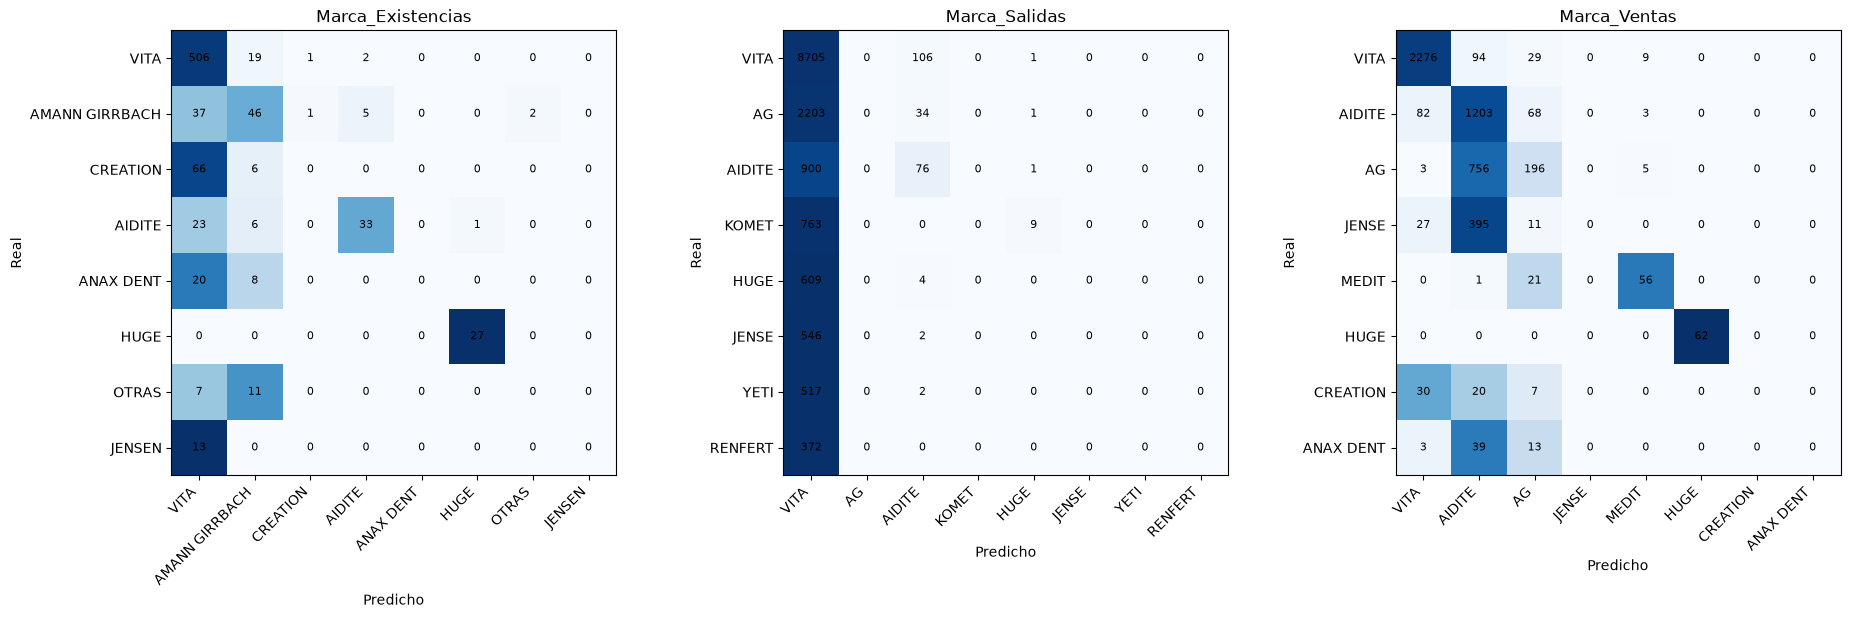

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for ax, v in zip(axes, analisis):
    m, clases = matrices[v]
    n = 8
    top = np.argsort(-m.sum(axis=1))[:n]
    mm = m[np.ix_(top, top)]
    nom = [clases[i] for i in top]
    ax.imshow(mm / m.sum(axis=1)[top][:, None], cmap='Blues')
    ax.set_xticks(range(n))
    ax.set_xticklabels(nom, rotation=45, ha='right')
    ax.set_yticks(range(n))
    ax.set_yticklabels(nom)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, mm[i, j], ha='center', va='center', fontsize=8)
    ax.set_title(v)
    ax.set_xlabel('Predicho')
    ax.set_ylabel('Real')
plt.tight_layout()
fig.savefig(DIRECTORIO_GRAFICAS / "complementarios_matrices_confusion_marcas.png", dpi=180, bbox_inches="tight")
plt.show()

## 4. Análisis CRM, compras, salidas y metas

Integra los cinco modelos del script Python. Guarda tablas limpias y reporte en `resultados_integrados/`; guarda las gráficas PNG en `resultados_integrados/graficas/`.

In [19]:
"""
Actividad 9 - Regresión Logística Multinomial
Socio formador: CLV

Archivos de entrada (en la misma carpeta que este script):
    - Datos_CLV_2026_Tec_v2.xlsx
    - Datos_Complementarios_CLV.xlsx

NO se usan las hojas de Ventas ni de Existencias.
Hojas utilizadas: Negocios_CRM, Histórico_Compras, Clasificación_Articulos,
Salidas_Almacen y Metas.

Modelos (5 variables categóricas objetivo):
    1. Resultado del negocio CRM      -> Ganado / Perdido / En proceso
    2. Valor del negocio CRM          -> Bajo / Medio / Alto
    3. Precio unitario de compra      -> Bajo / Medio / Alto
    4. Rotación de salidas de almacén -> Baja / Media / Alta
    5. Meta mensual por estado        -> Baja / Media / Alta

Para cada modelo: matriz de confusión, exactitud, precisión y sensibilidad.

Uso:
    python3 actividad9_rlm.py
Los resultados se guardan en la carpeta resultados/.
"""

import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

# =============================================================================
# CONFIGURACIÓN
# =============================================================================
BASE_DIR = DIRECTORIO_ACT9
ARCHIVO_PRINCIPAL = RUTA_PRINCIPAL
ARCHIVO_COMPLEMENTARIO = RUTA_COMPLEMENTARIA
RESULTADOS_DIR = DIRECTORIO_RESULTADOS

TEST_SIZE = 0.30
RANDOM_STATE = 42
UMBRAL_NULOS = 0.50      # columnas con más de 50 % de nulos se eliminan
MAX_CATEGORIAS = 40      # categorías máximas por variable de texto (el resto -> "Otros")

LOG = []


def registrar(texto=""):
    print(texto)
    LOG.append(str(texto))


# =============================================================================
# 1. CARGA
# =============================================================================
def cargar_hojas():
    if not ARCHIVO_PRINCIPAL.exists():
        raise FileNotFoundError(f"No se encontró {ARCHIVO_PRINCIPAL.name} junto al script")

    hojas = ["Negocios_CRM", "Histórico_Compras", "Clasificación_Articulos",
             "Salidas_Almacen", "Metas"]
    registrar("Leyendo Excel (puede tardar unos segundos)...")
    datos = pd.read_excel(ARCHIVO_PRINCIPAL, sheet_name=hojas)

    # Las hojas de Ventas y Existencias quedan fuera a propósito
    for nombre, df in datos.items():
        df.columns = [str(c).strip() for c in df.columns]
        df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")],
                inplace=True)
        registrar(f"  {nombre}: {df.shape[0]} filas x {df.shape[1]} columnas")
    return datos


# =============================================================================
# 2. PREPROCESAMIENTO GENERAL
# =============================================================================
def a_numero(serie):
    return pd.to_numeric(serie.astype(str).str.replace(r"[\$,\s]", "", regex=True),
                         errors="coerce")


def a_fecha(serie):
    return pd.to_datetime(serie, errors="coerce", utc=True)


def limpiar_texto(serie):
    s = serie.astype(str).str.strip().str.title()
    return s.replace({"Nan": np.nan, "None": np.nan, "": np.nan, "0": np.nan})


def agrupar_raras(serie, max_cat=MAX_CATEGORIAS):
    top = serie.value_counts().index[:max_cat]
    return serie.where(serie.isin(top), "Otros")


def tratar_nulos(df, nombre):
    nulos = df.isna().mean()
    if (nulos > 0).any():
        registrar(f"  Nulos (%):\n{(nulos[nulos > 0] * 100).round(2).to_string()}")
    else:
        registrar("  Sin valores nulos")
    eliminar = nulos[nulos > UMBRAL_NULOS].index.tolist()
    if eliminar:
        df = df.drop(columns=eliminar)
        registrar(f"  Columnas eliminadas (>{UMBRAL_NULOS:.0%} nulos): {eliminar}")
    for c in df.columns:
        if pd.api.types.is_numeric_dtype(df[c]):
            df[c] = df[c].fillna(df[c].median())
        else:
            moda = df[c].mode()
            df[c] = df[c].fillna(moda.iloc[0] if not moda.empty else "Desconocido")
    registrar("  Imputación: mediana (numéricas) y moda (categóricas)")
    return df


def tratar_outliers(df, columnas):
    """Recorta valores fuera de [Q1 - 1.5 IQR, Q3 + 1.5 IQR]."""
    resumen = {}
    for c in columnas:
        q1, q3 = df[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        if iqr == 0:
            continue
        li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n = int(((df[c] < li) | (df[c] > ls)).sum())
        if n:
            resumen[c] = n
            df[c] = df[c].clip(li, ls)
    registrar("  Outliers recortados (IQR): " + (str(resumen) if resumen else "ninguno"))
    return df


def transformar_log(df, columnas):
    """log1p para variables positivas con sesgo alto."""
    aplicadas = []
    for c in columnas:
        if df[c].min() >= 0 and abs(df[c].skew()) > 1:
            df[c] = np.log1p(df[c])
            aplicadas.append(c)
    registrar("  Transformación log1p: " + (str(aplicadas) if aplicadas else "ninguna"))
    return df


def encabezado(titulo):
    registrar("\n" + "=" * 70)
    registrar(titulo)
    registrar("=" * 70)


# =============================================================================
# 3. PREPARACIÓN DE CADA CONJUNTO + CATEGORIZACIÓN
# =============================================================================
def preparar_crm(df):
    encabezado("PREPROCESAMIENTO: Negocios_CRM")
    df = df.drop_duplicates(subset="id_negocio").copy()

    # Tipos
    for c in ["numero_actividades", "valor_negocio", "valor_previsto"]:
        df[c] = a_numero(df[c])
    fc = a_fecha(df["fecha_creacion"])
    df["mes_creacion"] = fc.dt.month
    df["dia_semana_creacion"] = fc.dt.dayofweek
    df["anio_creacion"] = fc.dt.year

    for c in ["estado", "tipo_negocio", "nombre_zona", "nombre_pipeline",
              "nombre_etapa", "vendedor"]:
        df[c] = limpiar_texto(df[c])

    # Corrección de valores mal capturados
    df.loc[~df["tipo_negocio"].isin(["Cliente Existente", "Cliente Nuevo"]),
           "tipo_negocio"] = np.nan
    df.loc[~df["nombre_zona"].astype(str).str.startswith("Zona"), "nombre_zona"] = np.nan
    df["nombre_pipeline"] = agrupar_raras(df["nombre_pipeline"].fillna("Otros"), 4)

    # Variable categórica 1: resultado del negocio
    etapa = df["nombre_etapa"].fillna("")
    df["resultado_negocio"] = np.select(
        [etapa.str.contains("Ganado"), etapa.str.contains("Perdido")],
        ["Ganado", "Perdido"], default="En Proceso")

    # Se descartan columnas que son identificadores, texto libre
    # o que revelan el resultado (fuga de información)
    df = df[["estado", "tipo_negocio", "nombre_zona", "nombre_pipeline", "vendedor",
             "numero_actividades", "valor_negocio", "mes_creacion",
             "dia_semana_creacion", "anio_creacion", "resultado_negocio"]]
    df = tratar_nulos(df, "CRM")
    df["estado"] = agrupar_raras(df["estado"], 20)
    df["vendedor"] = agrupar_raras(df["vendedor"], 15)
    df = tratar_outliers(df, ["numero_actividades", "valor_negocio"])

    # Variable categórica 2: nivel de valor del negocio (terciles)
    df["nivel_valor_negocio"] = categorizar_terciles(df["valor_negocio"],
                                                     ["Bajo", "Medio", "Alto"])
    registrar(f"  resultado_negocio: {df['resultado_negocio'].value_counts().to_dict()}")
    registrar(f"  nivel_valor_negocio: {df['nivel_valor_negocio'].value_counts().to_dict()}")
    return df


def categoria_principal(clasif):
    """Primera categoría registrada para cada artículo."""
    clasif = clasif.copy()
    clasif["categoria"] = limpiar_texto(clasif["categoria"])
    return (clasif.dropna(subset=["categoria"])
            .drop_duplicates(subset="articulo_id")[["articulo_id", "categoria"]])


def preparar_compras(df, cat):
    encabezado("PREPROCESAMIENTO: Histórico_Compras + Clasificación_Articulos")
    n0 = len(df)
    df = df.drop_duplicates().copy()
    registrar(f"  Duplicados eliminados: {n0 - len(df)}")
    df["unidades"] = a_numero(df["unidades"])
    df["precio_unitario"] = a_numero(df["precio_unitario"])
    f = a_fecha(df["fecha"])
    df["anio"] = f.dt.year
    df["mes"] = f.dt.month
    df = df.merge(cat, on="articulo_id", how="left")
    df["categoria"] = agrupar_raras(df["categoria"].fillna("Sin Clasificar"), 25)

    df = df[["unidades", "anio", "mes", "categoria", "precio_unitario"]]
    df = tratar_nulos(df, "Compras")
    # Variable categórica 3: rango de precio unitario (antes de recortar outliers)
    df["rango_precio_compra"] = categorizar_terciles(df["precio_unitario"],
                                                     ["Bajo", "Medio", "Alto"])
    df = tratar_outliers(df, ["unidades"])
    registrar(f"  rango_precio_compra: {df['rango_precio_compra'].value_counts().to_dict()}")
    return df.drop(columns="precio_unitario")


def preparar_salidas(df, cat):
    encabezado("PREPROCESAMIENTO: Salidas_Almacen + Clasificación_Articulos")
    n0 = len(df)
    df = df.drop_duplicates().copy()
    registrar(f"  Duplicados eliminados: {n0 - len(df)}")
    df["salidas"] = a_numero(df["salidas"])
    df["marca"] = agrupar_raras(limpiar_texto(df["marca"]), 20)
    df = df.merge(cat, on="articulo_id", how="left")
    df["categoria"] = agrupar_raras(df["categoria"].fillna("Sin Clasificar"), 25)
    df = df[["anio", "mes", "marca", "categoria", "salidas"]]
    df = tratar_nulos(df, "Salidas")

    # Variable categórica 4: rotación (rangos definidos por negocio)
    df["rotacion"] = pd.cut(df["salidas"], bins=[0, 2, 10, np.inf],
                            labels=["Baja", "Media", "Alta"]).astype(str)
    registrar("  Rotación: Baja (1-2 uds), Media (3-10 uds), Alta (>10 uds)")
    registrar(f"  rotacion: {df['rotacion'].value_counts().to_dict()}")
    return df.drop(columns="salidas")


def preparar_metas(df):
    encabezado("PREPROCESAMIENTO: Metas")
    df = df.drop_duplicates(subset="meta_id").copy()
    df["meta"] = a_numero(df["meta"])
    df["estado"] = limpiar_texto(df["estado"])
    df = df[["estado", "mes", "anio", "meta"]]
    df = tratar_nulos(df, "Metas")
    sin_meta = int((df["meta"] == 0).sum())
    df = df[df["meta"] > 0]
    registrar(f"  Registros con meta = 0 eliminados: {sin_meta}")
    df = tratar_outliers(df, ["meta"])
    # Variable categórica 5: nivel de meta (terciles)
    df["nivel_meta"] = categorizar_terciles(df["meta"], ["Baja", "Media", "Alta"])
    registrar(f"  nivel_meta: {df['nivel_meta'].value_counts().to_dict()}")
    return df.drop(columns="meta")


def categorizar_terciles(serie, etiquetas):
    try:
        return pd.qcut(serie, q=3, labels=etiquetas).astype(str)
    except ValueError:  # muchos valores repetidos
        return pd.qcut(serie.rank(method="first"), q=3, labels=etiquetas).astype(str)


# =============================================================================
# 4. REGRESIÓN LOGÍSTICA MULTINOMIAL
# =============================================================================
def modelo_rlm(n, df, objetivo, quitar, orden_clases, titulo):
    encabezado(f"MODELO {n}: {titulo}")
    y = df[objetivo].astype(str)
    X = df.drop(columns=[objetivo] + quitar)

    num = X.select_dtypes(include="number").columns.tolist()
    cat = X.select_dtypes(exclude="number").columns.tolist()
    X = transformar_log(X.copy(), [c for c in num if X[c].nunique() > 12])

    registrar(f"  Clases: {y.value_counts().to_dict()}")
    registrar(f"  Predictores numéricos: {num}")
    registrar(f"  Predictores categóricos: {cat}")

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

    pipe = Pipeline([
        ("prep", ColumnTransformer([
            ("num", StandardScaler(), num),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
        ])),
        # lbfgs con 3 clases => regresión logística multinomial (softmax)
        ("rlm", LogisticRegression(solver="lbfgs", max_iter=5000,
                                   class_weight="balanced",
                                   random_state=RANDOM_STATE)),
    ])
    pipe.fit(X_tr, y_tr)
    y_pred = pipe.predict(X_te)

    clases = [c for c in orden_clases if c in y.unique()]
    cm = confusion_matrix(y_te, y_pred, labels=clases)
    met = {
        "modelo": n,
        "variable_objetivo": objetivo,
        "descripcion": titulo,
        "exactitud": accuracy_score(y_te, y_pred),
        "precision_macro": precision_score(y_te, y_pred, average="macro", zero_division=0),
        "sensibilidad_macro": recall_score(y_te, y_pred, average="macro", zero_division=0),
        "precision_ponderada": precision_score(y_te, y_pred, average="weighted", zero_division=0),
        "sensibilidad_ponderada": recall_score(y_te, y_pred, average="weighted", zero_division=0),
    }

    registrar("\n  Matriz de confusión (filas = real, columnas = predicción):")
    registrar(pd.DataFrame(cm, index=clases, columns=clases).to_string())
    registrar(f"\n  Exactitud (accuracy):    {met['exactitud']:.4f}")
    registrar(f"  Precisión (macro):       {met['precision_macro']:.4f}")
    registrar(f"  Sensibilidad (macro):    {met['sensibilidad_macro']:.4f}")
    registrar("\n  Reporte por clase:")
    registrar(classification_report(y_te, y_pred, labels=clases, zero_division=0))

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=clases, yticklabels=clases)
    plt.xlabel("Predicción")
    plt.ylabel("Real")
    plt.title(f"Modelo {n}: {titulo}")
    plt.tight_layout()
    plt.savefig(DIRECTORIO_GRAFICAS / f"matriz_confusion_{n}_{objetivo}.png", dpi=180, bbox_inches="tight")
    plt.close()
    return met


def grafica_resumen(res):
    d = res.set_index("variable_objetivo")[
        ["exactitud", "precision_macro", "sensibilidad_macro"]]
    d.columns = ["Exactitud", "Precisión", "Sensibilidad"]
    ax = d.plot(kind="bar", figsize=(10, 5), color=["#2a6fdb", "#e3893b", "#3aa66b"])
    ax.set_ylim(0, 1)
    ax.set_ylabel("Valor")
    ax.set_xlabel("")
    ax.set_title("Métricas por modelo - Regresión Logística Multinomial (CLV)")
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.savefig(DIRECTORIO_GRAFICAS / "resumen_metricas.png", dpi=180, bbox_inches="tight")
    plt.close()

def main():
    RESULTADOS_DIR.mkdir(exist_ok=True)
    registrar("ACTIVIDAD 9 - REGRESIÓN LOGÍSTICA MULTINOMIAL (CLV)")
    datos = cargar_hojas()
    cat = categoria_principal(datos["Clasificación_Articulos"])

    crm = preparar_crm(datos["Negocios_CRM"])
    compras = preparar_compras(datos["Histórico_Compras"], cat)
    salidas = preparar_salidas(datos["Salidas_Almacen"], cat)
    metas = preparar_metas(datos["Metas"])

    for nombre, df in [("crm", crm), ("compras", compras),
                       ("salidas", salidas), ("metas", metas)]:
        df.to_csv(RESULTADOS_DIR / f"datos_limpios_{nombre}.csv", index=False)

    nivel3 = ["Bajo", "Medio", "Alto"]
    nivel3f = ["Baja", "Media", "Alta"]
    resultados = [
        modelo_rlm(1, crm, "resultado_negocio", ["nivel_valor_negocio"],
                   ["Ganado", "Perdido", "En Proceso"], "Resultado del negocio CRM"),
        modelo_rlm(2, crm, "nivel_valor_negocio", ["valor_negocio"],
                   nivel3, "Nivel de valor del negocio CRM"),
        modelo_rlm(3, compras, "rango_precio_compra", [],
                   nivel3, "Rango de precio unitario de compra"),
        modelo_rlm(4, salidas, "rotacion", [],
                   nivel3f, "Rotación de salidas de almacén"),
        modelo_rlm(5, metas, "nivel_meta", [],
                   nivel3f, "Nivel de meta mensual por estado"),
    ]

    res = pd.DataFrame(resultados)
    res.round(4).to_csv(RESULTADOS_DIR / "resumen_metricas.csv", index=False)
    grafica_resumen(res)

    encabezado("RESUMEN DE MÉTRICAS")
    registrar(res[["modelo", "variable_objetivo", "exactitud",
                   "precision_macro", "sensibilidad_macro"]].round(4).to_string(index=False))

    (RESULTADOS_DIR / "reporte.txt").write_text("\n".join(LOG), encoding="utf-8")
    print(f"\nResultados guardados en: {RESULTADOS_DIR}")


if __name__ == "__main__":
    main() 

ACTIVIDAD 9 - REGRESIÓN LOGÍSTICA MULTINOMIAL (CLV)
Leyendo Excel (puede tardar unos segundos)...
  Negocios_CRM: 5268 filas x 19 columnas
  Histórico_Compras: 9186 filas x 8 columnas
  Clasificación_Articulos: 18462 filas x 3 columnas
  Salidas_Almacen: 27474 filas x 9 columnas
  Metas: 756 filas x 8 columnas

PREPROCESAMIENTO: Negocios_CRM
  Nulos (%):
estado                  2.83
tipo_negocio           10.69
nombre_zona            21.70
vendedor                7.71
numero_actividades      0.44
valor_negocio           0.44
mes_creacion            0.57
dia_semana_creacion     0.57
anio_creacion           0.57
  Imputación: mediana (numéricas) y moda (categóricas)
  Outliers recortados (IQR): {'numero_actividades': 432}
  resultado_negocio: {'Ganado': 4099, 'Perdido': 934, 'En Proceso': 235}
  nivel_valor_negocio: {'Alto': 1756, 'Bajo': 1756, 'Medio': 1756}

PREPROCESAMIENTO: Histórico_Compras + Clasificación_Articulos
  Duplicados eliminados: 149
  Sin valores nulos
  Imputación: medi

In [20]:
main()

ACTIVIDAD 9 - REGRESIÓN LOGÍSTICA MULTINOMIAL (CLV)
Leyendo Excel (puede tardar unos segundos)...
  Negocios_CRM: 5268 filas x 19 columnas
  Histórico_Compras: 9186 filas x 8 columnas
  Clasificación_Articulos: 18462 filas x 3 columnas
  Salidas_Almacen: 27474 filas x 9 columnas
  Metas: 756 filas x 8 columnas

PREPROCESAMIENTO: Negocios_CRM
  Nulos (%):
estado                  2.83
tipo_negocio           10.69
nombre_zona            21.70
vendedor                7.71
numero_actividades      0.44
valor_negocio           0.44
mes_creacion            0.57
dia_semana_creacion     0.57
anio_creacion           0.57
  Imputación: mediana (numéricas) y moda (categóricas)
  Outliers recortados (IQR): {'numero_actividades': 432}
  resultado_negocio: {'Ganado': 4099, 'Perdido': 934, 'En Proceso': 235}
  nivel_valor_negocio: {'Alto': 1756, 'Bajo': 1756, 'Medio': 1756}

PREPROCESAMIENTO: Histórico_Compras + Clasificación_Articulos
  Duplicados eliminados: 149
  Sin valores nulos
  Imputación: medi

## 5. Regresión Logística Multinomial para Negocios_CRM

Se integra el flujo completo de preparación, predicción, evaluación, comparación de clases balanceadas y conclusiones de `9_RL_Multinomial_Negocios_CRM.ipynb`. Las matrices de confusión también se guardan como PNG.

**REGRESIÓN LOGÍSTICA MULTINOMIAL SOBRE LA HOJA Negocios_CRM**

En este cuaderno se aplica una regresión logística multinomial a la hoja Negocios_CRM del archivo Datos_CLV_2026_Tec_v2.xlsx.

La variable objetivo es el desenlace del negocio, construida a partir de nombre_etapa y agrupada en tres categorías: Ganado, Perdido y En proceso. El propósito es estimar en cuál de esos tres desenlaces termina una oportunidad comercial a partir de su valor, su actividad registrada, su antigüedad, su canal y su responsable.

La hoja requiere limpieza previa, por lo que el cuaderno inicia con una sección de preprocesamiento.

In [ ]:
# Cargamos librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    accuracy_score,
    recall_score,
    f1_score,
    classification_report
)

In [ ]:
# Cargamos la hoja Negocios_CRM del archivo de Excel
df = pd.read_excel(RUTA_PRINCIPAL, sheet_name="Negocios_CRM")

In [ ]:
df.head()

In [ ]:
# Revisamos el tamaño de la hoja y el tipo de dato de cada columna
print('Registros y columnas:')
print(df.shape)
df.info()

In [ ]:
# Revisamos los valores nulos de cada columna
df.isna().sum()

**PREPROCESAMIENTO**

La hoja presenta cuatro problemas que deben resolverse antes de modelar: una columna sin nombre, un grupo de registros con las columnas desalineadas, columnas numéricas almacenadas como texto y categorías con valores que no corresponden a la columna.

In [ ]:
# La columna Unnamed: 19 no forma parte del diccionario de datos
# Contiene valores de zona que se desplazaron desde la columna anterior
print('Valores de la columna sin nombre:')
print(df['Unnamed: 19'].value_counts(dropna=False))

In [ ]:
# Eliminamos la columna sin nombre
df = df.drop(columns=['Unnamed: 19'])

In [ ]:
# Detectamos los registros con las columnas desalineadas
# Un grupo se reconoce porque numero_actividades contiene una fecha en lugar de un entero
# Otro grupo se reconoce porque fecha_creacion contiene un texto de estatus
actividades = pd.to_numeric(df['numero_actividades'], errors='coerce')
fechas = pd.to_datetime(df['fecha_creacion'], errors='coerce', utc=True, format='ISO8601')
desalineados = (actividades.isna() & df['numero_actividades'].notna()) | fechas.isna()
print('Registros desalineados:')
print(desalineados.sum())
df.loc[desalineados, ['nombre_negocio', 'estado', 'numero_actividades', 'fecha_creacion']].head(10)

In [ ]:
# Eliminamos los registros desalineados porque sus campos no son recuperables
df = df.loc[~desalineados].copy()
print('Registros restantes:')
print(len(df))

In [ ]:
# Convertimos a número las columnas que llegaron como texto
df['numero_actividades'] = pd.to_numeric(df['numero_actividades'], errors='coerce').fillna(0)
df['valor_negocio'] = pd.to_numeric(df['valor_negocio'], errors='coerce')
df['valor_previsto'] = pd.to_numeric(df['valor_previsto'], errors='coerce').fillna(0)

In [ ]:
# Verificamos si valor_negocio y valor_previsto contienen la misma información
iguales = (df['valor_previsto'] == df['valor_negocio']).sum()
print('Registros donde valor_previsto coincide con valor_negocio:')
print(iguales, 'de', df['valor_negocio'].notna().sum())

In [ ]:
# Las dos columnas son equivalentes, conservamos solo valor_previsto
df = df.drop(columns=['valor_negocio'])

In [ ]:
# Convertimos las columnas de fecha
# El reporte mezcla marcas de tiempo con y sin milisegundos, por eso se indica ISO8601
df['fecha_creacion'] = pd.to_datetime(df['fecha_creacion'], errors='coerce', utc=True, format='ISO8601')
df['fecha_cierre'] = pd.to_datetime(df['fecha_cierre'], errors='coerce', utc=True, format='ISO8601')
print('Rango de fechas de creación:')
print(df['fecha_creacion'].min(), 'a', df['fecha_creacion'].max())

In [ ]:
# Construimos las variables derivadas
# La fecha de corte es la última creación registrada en la hoja
fecha_corte = df['fecha_creacion'].max()
df['antiguedad_dias'] = (fecha_corte - df['fecha_creacion']).dt.total_seconds() / 86400
df['mes_creacion'] = df['fecha_creacion'].dt.month
df['log_valor'] = np.log1p(df['valor_previsto'])
df['tiene_valor'] = (df['valor_previsto'] > 0).astype(int)
print('Fecha de corte:')
print(fecha_corte)

In [ ]:
# El 83 por ciento de los negocios tiene valor cero, por eso separamos
# la magnitud del monto de la simple presencia de un monto
print('Negocios con valor previsto mayor que cero:')
print(df['tiene_valor'].sum(), 'de', len(df))

In [ ]:
# Revisamos las categorías de las columnas que se usarán como predictoras
for columna in ['tipo_negocio', 'nombre_pipeline', 'oportunidad_ruta', 'nombre_zona']:
    print('---', columna)
    print(df[columna].value_counts(dropna=False))
    print()

In [ ]:
# Las columnas categóricas contienen valores que pertenecen a otras columnas
# Conservamos únicamente las categorías válidas y el resto queda como nulo
df['tipo_negocio'] = df['tipo_negocio'].where(
    df['tipo_negocio'].isin(['Cliente existente', 'Cliente nuevo']))

df['nombre_pipeline'] = df['nombre_pipeline'].where(
    df['nombre_pipeline'].isin(['Pipeline De Ventas', 'Ventas - Main',
                                'Mapeo En Ruta', 'Educación Contínua']))

df['oportunidad_ruta'] = df['oportunidad_ruta'].where(
    df['oportunidad_ruta'].isin(['No', 'Si', 'Mapeo En Ruta']))

df['nombre_zona'] = df['nombre_zona'].where(
    df['nombre_zona'].isin(['Zona Metropolitana', 'Zona Sur Este Golfo de México',
                            'Zona Bajío', 'Zona Occidente Pacífico', 'Zona Noreste']))

In [ ]:
# El vendedor es relevante para el cierre, pero tiene 32 categorías
# Agrupamos en Otros a los vendedores con menos de 30 negocios registrados
conteo_vendedor = df['vendedor'].value_counts()
vendedores_frecuentes = conteo_vendedor[conteo_vendedor >= 30].index
df['vendedor'] = df['vendedor'].where(df['vendedor'].isin(vendedores_frecuentes), 'Otros')
print('Categorías de vendedor conservadas:')
print(len(vendedores_frecuentes))

In [ ]:
# Rellenamos los nulos de las columnas categóricas con una categoría propia
# Un dato ausente en el CRM es informativo, no equivale a un valor promedio
for columna in ['tipo_negocio', 'nombre_pipeline', 'oportunidad_ruta', 'nombre_zona']:
    df[columna] = df[columna].fillna('Sin dato')

**CONSTRUCCIÓN DE LA VARIABLE OBJETIVO**

La columna nombre_etapa contiene 19 etapas distintas, varias de ellas con menos de diez registros y con nombres duplicados por errores de captura. Agrupamos esas etapas en tres desenlaces para obtener categorías con volumen suficiente.

In [ ]:
# Revisamos los valores de la columna de etapa
df['nombre_etapa'].value_counts(dropna=False)

In [ ]:
# Agrupamos las etapas en tres desenlaces
# Las etapas intermedias forman la categoría En proceso
mapa_desenlace = {
    'Cierre Ganado': 'Ganado',
    'Ganado': 'Ganado',
    'Recepción De Pago': 'Ganado',
    'Cierre Perdido': 'Perdido',
    'Perdido': 'Perdido'
}
df['desenlace'] = df['nombre_etapa'].map(mapa_desenlace)
etapas_intermedias = df['nombre_etapa'].notna() & df['desenlace'].isna()
df.loc[etapas_intermedias, 'desenlace'] = 'En proceso'

In [ ]:
# Revisamos los valores de la variable objetivo
df['desenlace'].value_counts(dropna=False)

In [ ]:
# Eliminamos los registros que no tienen categoría objetivo
df = df.dropna(subset=['desenlace']).copy()
print('Registros disponibles para el modelo:')
print(len(df))

In [ ]:
# Rellenamos con la mediana los nulos que pudieran quedar en las variables numéricas
for columna in ['numero_actividades', 'antiguedad_dias', 'mes_creacion', 'log_valor']:
    df[columna] = df[columna].fillna(df[columna].median())
print('Nulos restantes en las variables numéricas:')
print(df[['numero_actividades', 'antiguedad_dias', 'mes_creacion', 'log_valor']].isna().sum().sum())

**SELECCIÓN DE VARIABLES PREDICTORAS**

Tres columnas de la hoja anticipan el desenlace porque se escriben después de que el negocio se cierra, por lo que se excluyen del modelo.

La columna estatus distingue entre Cerrado y Abierto, lo que equivale a separar los desenlaces definitivos de los que siguen en proceso. La columna motivo_cierre_perdido solo se captura cuando el negocio se pierde, de modo que su presencia identifica la categoría Perdido. La columna fecha_cierre guarda la fecha real para los negocios cerrados y la fecha estimada para los abiertos, por lo que cualquier variable derivada de ella mezcla dos significados distintos.

También se excluyen los identificadores, el nombre del negocio por ser texto libre, la fecha de última modificación por corresponder a la extracción del reporte, y la columna estado por representar la misma información geográfica que nombre_zona con mayor dispersión.

In [ ]:
# Declaramos las variables dependientes e independientes
# No incluimos estatus, motivo_cierre_perdido ni fecha_cierre por anticipar el desenlace
variables_numericas = ['numero_actividades', 'log_valor', 'tiene_valor',
                       'antiguedad_dias', 'mes_creacion']
variables_categoricas = ['tipo_negocio', 'nombre_pipeline', 'oportunidad_ruta',
                         'nombre_zona', 'vendedor']

Vars_Indep = df[variables_numericas + variables_categoricas]
Var_Dep = df['desenlace']

In [ ]:
# Convertimos las variables categóricas en variables indicadoras
Vars_Indep = pd.get_dummies(Vars_Indep, columns=variables_categoricas, drop_first=True).astype(float)
print('Variables predictoras después de la codificación:')
print(Vars_Indep.shape)

In [ ]:
#Redefinimos las variables
X = Vars_Indep
y = Var_Dep

In [ ]:
# Dividimos el conjunto de datos en entrenamiento y prueba
# stratify conserva, en lo posible, la proporción de cada clase
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.3, random_state=42, stratify=y)

In [ ]:
#Se escalan todos los datos
escalar = StandardScaler()

In [ ]:
# Ajustamos el escalador con los datos de entrenamiento
# y aplicamos la misma transformación a los datos de prueba
X_train = escalar.fit_transform(X_train)
X_test = escalar.transform(X_test)

In [ ]:
# Definimos el algoritmo de regresión logística multinomial
# Con más de dos clases, scikit-learn ajusta el modelo multinomial
algoritmo = LogisticRegression(
    solver='lbfgs',
    max_iter=2000
)

In [ ]:
#Entrenamos el modelo
algoritmo.fit(X_train, y_train)

In [ ]:
#Realizamos una predicción
y_pred = algoritmo.predict(X_test)
y_pred

In [ ]:
# Consultamos las categorías que predice el modelo
print('Clases del modelo:')
print(algoritmo.classes_)

In [ ]:
# Verificamos la matriz de confusión
matriz = confusion_matrix(y_test, y_pred, labels=algoritmo.classes_)
print('Matriz de confusión:')
print(matriz)

In [ ]:
# Visualizamos la matriz de confusión
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=algoritmo.classes_
)
disp.plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusión - Regresión logística multinomial')
plt.savefig(DIRECTORIO_GRAFICAS / "crm_matriz_confusion_sin_balancear.png", dpi=180, bbox_inches="tight")
plt.show()

In [ ]:
# Calculamos la precisión del modelo
# average='weighted' considera el número de observaciones de cada clase
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
print('Precisión ponderada del modelo:')
print(precision)

In [ ]:
# Calculamos la exactitud del modelo
exactitud = accuracy_score(y_test, y_pred)
print('Exactitud del modelo:')
print(exactitud)

In [ ]:
# Calculamos la sensibilidad (recall) ponderada
sensibilidad = recall_score(y_test, y_pred, average='weighted', zero_division=0)
print('Sensibilidad ponderada del modelo:')
print(sensibilidad)

In [ ]:
# Calculamos el puntaje F1 ponderado
puntajef1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
print('Puntaje F1 ponderado del modelo:')
print(puntajef1)

In [ ]:
# Comparamos la exactitud contra la regla de la clase mayoritaria
# Es el mínimo que debe superar cualquier modelo útil
referencia = y_test.value_counts(normalize=True).max()
print('Exactitud de la clase mayoritaria:')
print(referencia)
print('Ganancia del modelo en puntos porcentuales:')
print((exactitud - referencia) * 100)

In [ ]:
# Reporte de clasificación por cada categoría
print(classification_report(y_test, y_pred, zero_division=0))

In [ ]:
# Probabilidades estimadas para cada categoría
probabilidades = algoritmo.predict_proba(X_test)
df_probabilidades = pd.DataFrame(
    probabilidades,
    columns=[f'Probabilidad_{clase}' for clase in algoritmo.classes_]
)
df_probabilidades.head()

In [ ]:
# Comparamos la categoría real con la categoría predicha
comparacion = pd.DataFrame({
    'Clase real': y_test.reset_index(drop=True),
    'Clase predicha': pd.Series(y_pred)
})
comparacion.head(10)

**TABLA DE MÉTRICAS POR CATEGORÍA**

In [ ]:
# Concentramos la precisión, la sensibilidad y el puntaje F1 de cada categoría
Tabla_Metricas = pd.DataFrame({
    'Categoría': algoritmo.classes_,
    'Registros en prueba': [int((y_test == clase).sum()) for clase in algoritmo.classes_],
    'Precisión': precision_score(y_test, y_pred, labels=algoritmo.classes_, average=None, zero_division=0),
    'Sensibilidad': recall_score(y_test, y_pred, labels=algoritmo.classes_, average=None, zero_division=0),
    'Puntaje F1': f1_score(y_test, y_pred, labels=algoritmo.classes_, average=None, zero_division=0)
})
Tabla_Metricas

In [ ]:
# Agregamos las métricas globales del modelo
Tabla_Global = pd.DataFrame({
    'Métrica': ['Exactitud', 'Precisión ponderada', 'Sensibilidad ponderada',
                'Puntaje F1 ponderado', 'Puntaje F1 macro', 'Clase mayoritaria'],
    'Valor': [exactitud, precision, sensibilidad, puntajef1,
              f1_score(y_test, y_pred, average='macro', zero_division=0), referencia]
})
Tabla_Global

**MODELO COMPLEMENTARIO CON CLASES BALANCEADAS**

La categoría Ganado concentra el 78 por ciento de los registros, por lo que el modelo anterior tiende a asignar esa categoría y deja con baja sensibilidad a Perdido y a En proceso. Ajustamos un segundo modelo que pondera cada clase de forma inversa a su frecuencia para medir ese efecto.

In [ ]:
# Definimos el mismo algoritmo con ponderación inversa a la frecuencia de cada clase
algoritmo_balanceado = LogisticRegression(
    solver='lbfgs',
    max_iter=2000,
    class_weight='balanced'
)
algoritmo_balanceado.fit(X_train, y_train)

In [ ]:
#Realizamos la predicción del modelo balanceado
y_pred_balanceado = algoritmo_balanceado.predict(X_test)

In [ ]:
# Reporte de clasificación del modelo balanceado
print(classification_report(y_test, y_pred_balanceado, zero_division=0))

In [ ]:
# Visualizamos la matriz de confusión del modelo balanceado
matriz_balanceada = confusion_matrix(y_test, y_pred_balanceado, labels=algoritmo_balanceado.classes_)
disp2 = ConfusionMatrixDisplay(
    confusion_matrix=matriz_balanceada,
    display_labels=algoritmo_balanceado.classes_
)
disp2.plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusión - Modelo con clases balanceadas')
plt.savefig(DIRECTORIO_GRAFICAS / "crm_matriz_confusion_balanceada.png", dpi=180, bbox_inches="tight")
plt.show()

In [ ]:
# Comparamos los dos modelos
Tabla_Comparacion = pd.DataFrame({
    'Modelo': ['Sin ponderación', 'Con clases balanceadas'],
    'Exactitud': [exactitud, accuracy_score(y_test, y_pred_balanceado)],
    'Puntaje F1 ponderado': [puntajef1,
                             f1_score(y_test, y_pred_balanceado, average='weighted', zero_division=0)],
    'Puntaje F1 macro': [f1_score(y_test, y_pred, average='macro', zero_division=0),
                         f1_score(y_test, y_pred_balanceado, average='macro', zero_division=0)],
    'Sensibilidad Perdido': [recall_score(y_test, y_pred, labels=['Perdido'], average=None, zero_division=0)[0],
                             recall_score(y_test, y_pred_balanceado, labels=['Perdido'], average=None, zero_division=0)[0]],
    'Sensibilidad En proceso': [recall_score(y_test, y_pred, labels=['En proceso'], average=None, zero_division=0)[0],
                                recall_score(y_test, y_pred_balanceado, labels=['En proceso'], average=None, zero_division=0)[0]]
})
Tabla_Comparacion

**COEFICIENTES DEL MODELO**

La regresión logística multinomial ajusta un vector de coeficientes por cada categoría. Un coeficiente positivo indica que al aumentar esa variable crece la probabilidad de la categoría correspondiente frente a las demás. Como las variables fueron escaladas, los coeficientes son comparables entre sí.

In [ ]:
# Revisamos los coeficientes de cada categoría
Tabla_Coeficientes = pd.DataFrame(
    algoritmo.coef_.T,
    index=Vars_Indep.columns,
    columns=[f'Coeficiente_{clase}' for clase in algoritmo.classes_]
)
Tabla_Coeficientes.head(10)

In [ ]:
# Consultamos las cinco variables de mayor peso para cada categoría
for k, clase in enumerate(algoritmo.classes_):
    pesos = Tabla_Coeficientes[f'Coeficiente_{clase}']
    print('---', clase)
    print(pesos.reindex(pesos.abs().sort_values(ascending=False).index).head(5))
    print()

In [ ]:
# Revisamos el comportamiento de las variables numéricas en cada categoría
Tabla_Perfil = df.groupby('desenlace').agg(
    Registros=('desenlace', 'size'),
    Antiguedad_mediana_dias=('antiguedad_dias', 'median'),
    Actividades_mediana=('numero_actividades', 'median'),
    Proporcion_con_valor=('tiene_valor', 'mean')
).round(4)
Tabla_Perfil

**ANÁLISIS DE RESULTADOS**

El conjunto final quedó en 5245 registros y 39 variables predictoras, resultado de eliminar una columna sin nombre, 23 registros con las columnas desalineadas y la columna valor_negocio por ser idéntica a valor_previsto. Las fechas de creación abarcan de agosto de 2025 a septiembre de 2026.

La variable objetivo está muy desbalanceada. La categoría Ganado concentra 4100 registros que equivalen al 78.17 por ciento del total, Perdido reúne 934 registros con el 17.81 por ciento y En proceso apenas 211 registros con el 4.02 por ciento. Ese desbalance condiciona la lectura de todas las métricas.

El modelo alcanza una exactitud de 0.8463 frente a 0.7821 que obtendría la regla de asignar siempre la clase mayoritaria. La ganancia es de 6.42 puntos porcentuales, de modo que el modelo aporta información real pero moderada. La precisión ponderada es de 0.8291, la sensibilidad ponderada de 0.8463 y el puntaje F1 ponderado de 0.8281. El puntaje F1 macro, que trata a las tres categorías con el mismo peso, baja a 0.6386 y revela que el buen desempeño global descansa sobre la categoría mayoritaria.

El desglose por categoría confirma ese diagnóstico. Ganado obtiene una precisión de 0.8821 y una sensibilidad de 0.9724, por lo que el modelo identifica correctamente casi todos los negocios ganados. Perdido obtiene una precisión de 0.6667 pero una sensibilidad de solo 0.3643, es decir que el modelo detecta apenas un tercio de los negocios que efectivamente se perdieron. En proceso queda en un punto intermedio con 0.5156 de precisión y 0.5238 de sensibilidad sobre una base de 63 registros de prueba.

La matriz de confusión señala con precisión dónde falla el modelo. De los 280 negocios perdidos del conjunto de prueba, 102 se clasifican bien, 26 se asignan a En proceso y 152 se asignan a Ganado. Ese último bloque es el error dominante y el más costoso en términos de negocio, porque implica que el modelo pronostica un cierre favorable en negocios que terminaron perdiéndose. Un pronóstico con ese sesgo infla la expectativa de ingreso del pipeline.

**EFECTO DE LA PONDERACIÓN DE CLASES**

El modelo complementario con class_weight balanced invierte el compromiso. La sensibilidad de Perdido sube de 0.3643 a 0.5821 y la de En proceso sube de 0.5238 a 0.8730, lo que significa que el modelo ahora sí levanta la mayoría de los casos que antes pasaba por alto. El costo es que la exactitud cae a 0.7573, por debajo del 0.7821 de la clase mayoritaria, y el puntaje F1 macro baja ligeramente de 0.6386 a 0.6267 porque la precisión de las clases minoritarias se deteriora al emitir muchas más alertas.

Ninguno de los dos modelos domina al otro. La elección depende del uso: para estimar el volumen total de cierres conviene el modelo sin ponderación, y para detectar negocios en riesgo de perderse conviene el modelo ponderado, aceptando que generará falsas alarmas.

**LECTURA DE LOS COEFICIENTES**

Los coeficientes de mayor magnitud apuntan a nombre_pipeline, numero_actividades, antiguedad_dias y mes_creacion. El pipeline de ventas empuja con fuerza hacia Ganado con un coeficiente de 1.5595 y en contra de En proceso con menos 1.9089, lo que refleja que los negocios de ese canal se registran y cierran dentro del mismo flujo operativo. La antigüedad discrimina la categoría En proceso con un coeficiente de menos 1.0174, consistente con que los negocios abiertos son los más recientes: su antigüedad mediana es de 14.36 días contra 147.04 días en Ganado y 128.69 días en Perdido.

El hallazgo más llamativo es el signo de numero_actividades. Esta variable pesa menos 1.4824 para Ganado y más 0.7178 para Perdido, es decir que a mayor número de actividades registradas disminuye la probabilidad de un cierre favorable. La mediana de actividades es de cero en Ganado, uno en Perdido y dos en En proceso. La interpretación directa no es que dar seguimiento perjudique la venta, sino que los negocios que se ganan con facilidad se capturan en el CRM ya cerrados y sin actividades intermedias, mientras que los que exigen insistencia son precisamente los que se complican.

**CONCLUSIONES**

La regresión logística multinomial sobre la hoja Negocios_CRM supera la regla de la clase mayoritaria por 6.42 puntos de exactitud y distingue las tres categorías del desenlace, por lo que el ejercicio es válido. Dicho eso, el modelo solo es confiable para la categoría Ganado y presenta una debilidad clara en la detección de los negocios perdidos.

El desbalance de 78 contra 18 contra 4 por ciento es el principal limitante. Una exactitud de 0.8463 suena alta pero debe contrastarse siempre contra el 0.7821 del baseline, y el puntaje F1 macro de 0.6386 es la cifra que describe con honestidad el desempeño sobre las tres categorías. En problemas con esta estructura, reportar únicamente la exactitud transmite una impresión equivocada.

La calidad de los datos limita el alcance del modelo más que la técnica elegida. Veintitrés registros llegaron con las columnas desplazadas, varias columnas categóricas contenían valores de otras columnas, y el 83 por ciento de los negocios tiene valor previsto en cero, lo que vacía de contenido a la variable monetaria. Antes de refinar el modelo conviene corregir la captura en el origen.

Un punto metodológico que conviene explicitar: se descartaron estatus, motivo_cierre_perdido y cualquier variable derivada de fecha_cierre porque se escriben después del cierre y anticipan la respuesta. Al incluir los días de ciclo, la exactitud subía a 0.8602, pero esa ganancia es artificial y no estaría disponible al momento de pronosticar un negocio abierto. Se prefirió el modelo más conservador.

Queda abierta la observación sobre numero_actividades. El modelo aprende en buena medida el patrón de captura del CRM, donde las ventas que se cierran de inmediato se registran sin actividades previas. Eso significa que el modelo describe mejor cómo se registra la operación que cómo se comporta un negocio a futuro. Para un pronóstico genuinamente anticipado haría falta reconstruir el estado de cada negocio en un momento previo a su cierre y entrenar únicamente con la información disponible en esa fecha.